Interpret the final V2 ResNet50 model using Grad-CAM.

Grad-CAM (Gradient-weighted Class Activation Mapping) is used to visualize the spatial regions that contribute positively to a selected class prediction.

This notebook will:

1. Load the final fine-tuned ResNet50 model.
2. Load the locked test dataset.
3. Reconstruct the ResNet50 backbone + classification head without retraining.
4. Build a Grad-CAM-compatible model while preserving ResNet residual connections.
5. Verify that the reconstructed model produces the same predictions as the original V2 model.
6. Generate Grad-CAM heatmaps.
7. Analyze correct and incorrect predictions.
8. Investigate glioma → meningioma errors.
9. Examine high-confidence errors.


- No model retraining is performed.
- No test-set tuning is performed.
- The test set remains the locked final evaluation set.
- Grad-CAM provides qualitative interpretation only.
- Highlighted regions do not prove tumor localization or clinical validity.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import load_model
from tensorflow.keras.applications.resnet50 import preprocess_input
from sklearn.metrics import classification_report, confusion_matrix
SEED = 42

np.random.seed(SEED)
tf.random.set_seed(SEED)

In [2]:
CLASS_NAMES = [
    "glioma",
    "meningioma",
    "no_tumor",
    "pituitary"
]

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32

DATASET_DIR = Path(
    "../artifacts/data_ingestion/brisc2025/brisc2025/classification_task"
)

TEST_DIR = DATASET_DIR / "test"

MODEL_PATH = Path(
    "../artifacts/model_trainer/resnet50_finetuned.keras"
)

OUTPUT_DIR = Path(
    "../artifacts/model_interpretability"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("TEST_DIR:", TEST_DIR)
print("MODEL_PATH:", MODEL_PATH)
print("OUTPUT_DIR:", OUTPUT_DIR)

TEST_DIR: ..\artifacts\data_ingestion\brisc2025\brisc2025\classification_task\test
MODEL_PATH: ..\artifacts\model_trainer\resnet50_finetuned.keras
OUTPUT_DIR: ..\artifacts\model_interpretability


In [3]:
assert TEST_DIR.exists(), (
    f"Test directory not found: {TEST_DIR}"
)

assert MODEL_PATH.exists(), (
    f"Final model not found: {MODEL_PATH}"
)

print("Test directory verified.")
print("Final V2 model verified.")

Test directory verified.
Final V2 model verified.


In [4]:
test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Classes:", test_ds.class_names)

Found 1000 files belonging to 4 classes.
Classes: ['glioma', 'meningioma', 'no_tumor', 'pituitary']


In [5]:
assert test_ds.class_names == CLASS_NAMES

print("Class order:")
for i, class_name in enumerate(test_ds.class_names):
    print(f"{i} -> {class_name}")

Class order:
0 -> glioma
1 -> meningioma
2 -> no_tumor
3 -> pituitary


In [6]:
model = load_model(
    MODEL_PATH,
    custom_objects={
        "preprocess_input": preprocess_input
    },
    compile=False
)

print("Final V2 model loaded successfully.")


Final V2 model loaded successfully.


In [7]:
for index, layer in enumerate(model.layers):

    print(
        index,
        "|",
        layer.name,
        "|",
        layer.__class__.__name__
    )

0 | lambda | Lambda
1 | resnet50 | Functional
2 | global_average_pooling2d | GlobalAveragePooling2D
3 | batch_normalization | BatchNormalization
4 | dense | Dense
5 | dropout | Dropout
6 | dense_1 | Dense


In [8]:
resnet_layer = None

for layer in model.layers:

    if (
        isinstance(layer, tf.keras.Model)
        and "resnet50" in layer.name.lower()
    ):
        resnet_layer = layer
        break

if resnet_layer is None:

    raise ValueError(
        "ResNet50 backbone could not be found."
    )

print(
    "ResNet50 backbone:",
    resnet_layer.name
)

ResNet50 backbone: resnet50


#### Inspect final ResNet layers

In [9]:
for layer in resnet_layer.layers[-20:]:

    print(
        layer.name,
        "|",
        layer.__class__.__name__,
        "|",
        layer.output.shape
    )

conv5_block2_1_conv | Conv2D | (None, 7, 7, 512)
conv5_block2_1_bn | BatchNormalization | (None, 7, 7, 512)
conv5_block2_1_relu | Activation | (None, 7, 7, 512)
conv5_block2_2_conv | Conv2D | (None, 7, 7, 512)
conv5_block2_2_bn | BatchNormalization | (None, 7, 7, 512)
conv5_block2_2_relu | Activation | (None, 7, 7, 512)
conv5_block2_3_conv | Conv2D | (None, 7, 7, 2048)
conv5_block2_3_bn | BatchNormalization | (None, 7, 7, 2048)
conv5_block2_add | Add | (None, 7, 7, 2048)
conv5_block2_out | Activation | (None, 7, 7, 2048)
conv5_block3_1_conv | Conv2D | (None, 7, 7, 512)
conv5_block3_1_bn | BatchNormalization | (None, 7, 7, 512)
conv5_block3_1_relu | Activation | (None, 7, 7, 512)
conv5_block3_2_conv | Conv2D | (None, 7, 7, 512)
conv5_block3_2_bn | BatchNormalization | (None, 7, 7, 512)
conv5_block3_2_relu | Activation | (None, 7, 7, 512)
conv5_block3_3_conv | Conv2D | (None, 7, 7, 2048)
conv5_block3_3_bn | BatchNormalization | (None, 7, 7, 2048)
conv5_block3_add | Add | (None, 7, 7, 204

##### Select Grad-CAM target

In [10]:
target_layer = resnet_layer.get_layer(
    "conv5_block3_3_conv"
)

print("Selected Grad-CAM target:")
print("Name:", target_layer.name)
print("Type:", type(target_layer).__name__)
print("Input:", target_layer.input.shape)
print("Output:", target_layer.output.shape)

Selected Grad-CAM target:
Name: conv5_block3_3_conv
Type: Conv2D
Input: (None, 7, 7, 512)
Output: (None, 7, 7, 2048)


#### Build the Grad-CAM ResNet model

In [11]:
resnet_grad_model = tf.keras.models.Model(
    inputs=resnet_layer.input,
    outputs=[
        target_layer.output,
        resnet_layer.output
    ],
    name="resnet_grad_model"
)

print("Grad-CAM ResNet model created.")

print("\nInput:")
print(resnet_grad_model.input)

print("\nOutputs:")
for output in resnet_grad_model.outputs:
    print(output)

Grad-CAM ResNet model created.

Input:
<KerasTensor shape=(None, 224, 224, 3), dtype=float32, sparse=False, ragged=False, name=input_layer>

Outputs:
<KerasTensor shape=(None, 7, 7, 2048), dtype=float32, sparse=False, ragged=False, name=keras_tensor_359>
<KerasTensor shape=(None, 7, 7, 2048), dtype=float32, sparse=False, ragged=False, name=keras_tensor_366>


#### Build classification head

In [12]:
resnet_index = model.layers.index(
    resnet_layer
)

head_layers = model.layers[
    resnet_index + 1:
]

print("ResNet index:", resnet_index)

print("\nClassification head layers:")

for layer in head_layers:
    print(
        layer.name,
        "|",
        layer.__class__.__name__
    )

ResNet index: 1

Classification head layers:
global_average_pooling2d | GlobalAveragePooling2D
batch_normalization | BatchNormalization
dense | Dense
dropout | Dropout
dense_1 | Dense


#### Build classification head model

In [13]:
head_input = tf.keras.Input(
    shape=resnet_layer.output_shape[1:],
    name="resnet_output_input"
)

x = head_input

for layer in head_layers:
    x = layer(x)

head_model = tf.keras.Model(
    inputs=head_input,
    outputs=x,
    name="classification_head"
)

print("Classification head created.")

print("\nHead input:")
print(head_model.input)

print("\nHead output:")
print(head_model.output)

Classification head created.

Head input:
<KerasTensor shape=(None, 7, 7, 2048), dtype=float32, sparse=False, ragged=False, name=resnet_output_input>

Head output:
<KerasTensor shape=(None, 4), dtype=float32, sparse=False, ragged=False, name=keras_tensor_410>


In [14]:
# Verify Grad-CAM architecture
sample_images, sample_labels = next(iter(test_ds))

sample_image = sample_images[0:1]

print("Sample image shape:")
print(sample_image.shape)

Sample image shape:
(1, 224, 224, 3)


#### Preprocess sample

In [15]:
preprocessed_image = preprocess_input(
    tf.cast(
        sample_image,
        tf.float32
    )
)

print("Preprocessed image shape:")
print(preprocessed_image.shape)

Preprocessed image shape:
(1, 224, 224, 3)


#### Run Grad-CAM ResNet model

In [16]:
target_activation, resnet_output = resnet_grad_model(
    preprocessed_image,
    training=False
)

print("Target activation shape:")
print(target_activation.shape)

print("\nResNet output shape:")
print(resnet_output.shape)

Target activation shape:
(1, 7, 7, 2048)

ResNet output shape:
(1, 7, 7, 2048)


#### Run classification head

In [17]:
reconstructed_prediction = head_model(
    resnet_output,
    training=False
)

print("Reconstructed prediction shape:")
print(reconstructed_prediction.shape)

print("\nProbabilities:")
print(reconstructed_prediction.numpy())

Reconstructed prediction shape:
(1, 4)

Probabilities:
[[9.9802631e-01 3.5122182e-04 1.6154668e-03 6.9547618e-06]]


#### Verify against original model
Original V2 model
        vs
ResNet Grad-CAM model + classification head

In [18]:
original_prediction = model.predict(
    sample_image,
    verbose=0
)

reconstructed_prediction_np = (
    reconstructed_prediction.numpy()
)

print("Original prediction:")
print(original_prediction)

print("\nReconstructed prediction:")
print(reconstructed_prediction_np)

max_difference = np.max(
    np.abs(
        original_prediction
        - reconstructed_prediction_np
    )
)

print("\nMaximum probability difference:")
print(max_difference)

Original prediction:
[[9.9802631e-01 3.5122217e-04 1.6154584e-03 6.9547159e-06]]

Reconstructed prediction:
[[9.9802631e-01 3.5122182e-04 1.6154668e-03 6.9547618e-06]]

Maximum probability difference:
8.381903e-09


#### Verify predicted class

In [19]:
original_class = int(
    np.argmax(original_prediction[0])
)

reconstructed_class = int(
    np.argmax(reconstructed_prediction_np[0])
)

print(
    "Original predicted class:",
    CLASS_NAMES[original_class]
)

print(
    "Reconstructed predicted class:",
    CLASS_NAMES[reconstructed_class]
)

assert original_class == reconstructed_class

print("\nPrediction verification passed.")

Original predicted class: glioma
Reconstructed predicted class: glioma

Prediction verification passed.


#### Grad-CAM function

In [20]:
def make_gradcam_heatmap(
    image,
    class_index=None
):
    """
    Generate a Grad-CAM heatmap for one image.

    Parameters
    ----------
    image : Tensor
        Image with shape (1, 224, 224, 3).

    class_index : int or None
        Class for which Grad-CAM should be generated.
        If None, the predicted class is used.

    Returns
    -------
    heatmap : numpy.ndarray
        Heatmap with shape (7, 7).

    predicted_class : int
        Model predicted class index.

    probabilities : numpy.ndarray
        Four class probabilities.
    """

    image = tf.cast(
        image,
        tf.float32
    )

    processed_image = preprocess_input(
        image
    )

    with tf.GradientTape() as tape:

        target_activation, resnet_output = (
            resnet_grad_model(
                processed_image,
                training=False
            )
        )

        tape.watch(
            target_activation
        )

        predictions = head_model(
            resnet_output,
            training=False
        )

        predicted_class = tf.argmax(
            predictions[0]
        )

        if class_index is None:
            class_index = predicted_class

        class_score = predictions[
            :,
            class_index
        ]

    gradients = tape.gradient(
        class_score,
        target_activation
    )

    if gradients is None:
        raise ValueError(
            "Gradients could not be computed."
        )

    # Global average pooling of gradients
    pooled_gradients = tf.reduce_mean(
        gradients,
        axis=(1, 2)
    )

    # Remove batch dimension
    target_activation = target_activation[0]
    pooled_gradients = pooled_gradients[0]

    # Weight activation maps by gradient importance
    weighted_features = (
        target_activation
        * pooled_gradients
    )

    # Combine channels
    heatmap = tf.reduce_sum(
        weighted_features,
        axis=-1
    )

    # Keep only positive influence
    heatmap = tf.maximum(
        heatmap,
        0
    )

    # Normalize
    max_value = tf.reduce_max(
        heatmap
    )

    heatmap = tf.where(
        max_value > 0,
        heatmap / max_value,
        heatmap
    )

    return (
        heatmap.numpy(),
        int(predicted_class.numpy()),
        predictions.numpy()[0]
    )

In [21]:
heatmap, predicted_class, probabilities = (
    make_gradcam_heatmap(
        sample_image
    )
)

print("Heatmap shape:")
print(heatmap.shape)

print("\nPredicted class:")
print(CLASS_NAMES[predicted_class])

print("\nProbabilities:")
for class_name, probability in zip(
    CLASS_NAMES,
    probabilities
):
    print(
        f"{class_name}: {probability:.4f}"
    )

Heatmap shape:
(7, 7)

Predicted class:
glioma

Probabilities:
glioma: 0.9980
meningioma: 0.0004
no_tumor: 0.0016
pituitary: 0.0000


In [22]:
# Resize heatmap
def resize_heatmap(
    heatmap,
    image_size=IMAGE_SIZE
):
    heatmap_tensor = tf.convert_to_tensor(
        heatmap[..., np.newaxis],
        dtype=tf.float32
    )

    resized = tf.image.resize(
        heatmap_tensor,
        image_size
    )

    return resized.numpy().squeeze()

In [23]:
# Display Grad-CAM
def display_gradcam(
    image,
    heatmap,
    true_class,
    predicted_class,
    probabilities,
    alpha=0.4
):
    image = np.asarray(
        image
    ).astype("uint8")

    resized_heatmap = resize_heatmap(
        heatmap
    )

    confidence = probabilities[
        predicted_class
    ]

    plt.figure(
        figsize=(15, 5)
    )

    # Original
    plt.subplot(1, 3, 1)

    plt.imshow(
        image
    )

    plt.title(
        f"Original\n"
        f"True: {CLASS_NAMES[true_class]}"
    )

    plt.axis("off")

    # Heatmap
    plt.subplot(1, 3, 2)

    plt.imshow(
        resized_heatmap,
        cmap="jet"
    )

    plt.title(
        f"Grad-CAM\n"
        f"Predicted: {CLASS_NAMES[predicted_class]}"
    )

    plt.axis("off")

    # Overlay
    plt.subplot(1, 3, 3)

    plt.imshow(
        image
    )

    plt.imshow(
        resized_heatmap,
        cmap="jet",
        alpha=alpha
    )

    plt.title(
        f"Overlay\n"
        f"{CLASS_NAMES[predicted_class]} "
        f"({confidence:.2%})"
    )

    plt.axis("off")

    plt.tight_layout()

    plt.show()

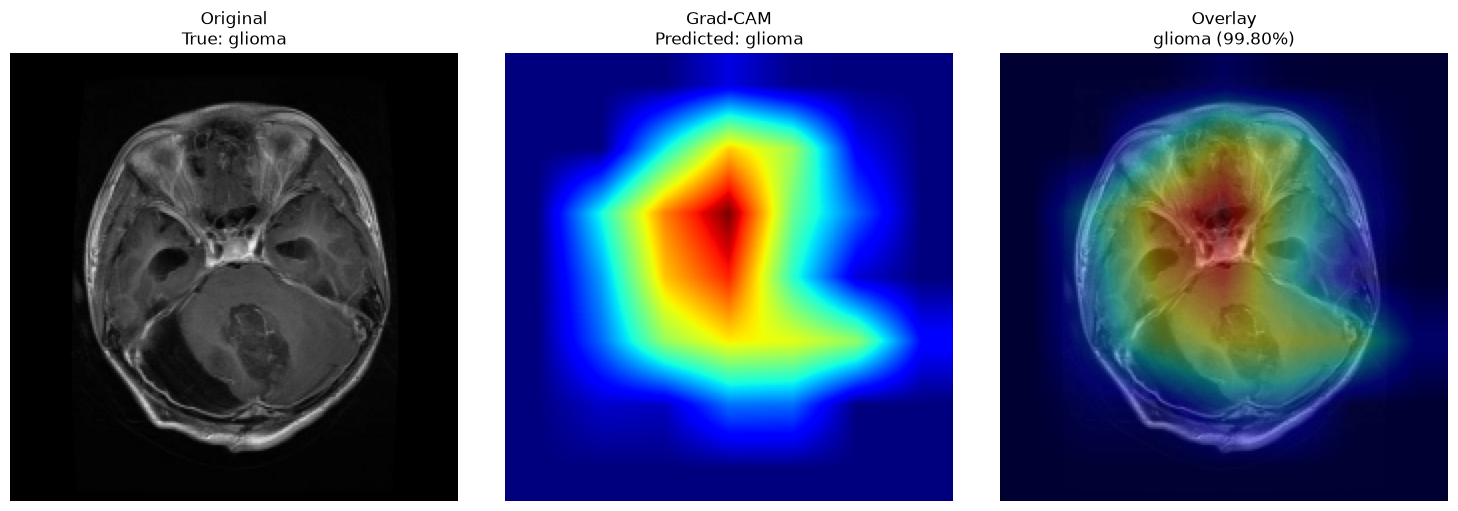

In [24]:
true_class = int(
    sample_labels[0].numpy()
)

display_gradcam(
    image=sample_image[0].numpy(),
    heatmap=heatmap,
    true_class=true_class,
    predicted_class=predicted_class,
    probabilities=probabilities
)

#### Generate predictions for entire test set

In [25]:
all_images = []
all_labels = []

for images, labels in test_ds:

    all_images.append(
        images.numpy()
    )

    all_labels.append(
        labels.numpy()
    )

all_images = np.concatenate(
    all_images,
    axis=0
)

all_labels = np.concatenate(
    all_labels,
    axis=0
)

print("All images shape:")
print(all_images.shape)

print("\nAll labels shape:")
print(all_labels.shape)

All images shape:
(1000, 224, 224, 3)

All labels shape:
(1000,)


#### Generate V2 predictions

In [26]:
all_probabilities = model.predict(
    all_images,
    batch_size=BATCH_SIZE,
    verbose=1
)

all_predictions = np.argmax(
    all_probabilities,
    axis=1
)

print("Probability shape:")
print(all_probabilities.shape)

print("\nPrediction shape:")
print(all_predictions.shape)

32/32 ━━━━━━━━━━━━━━━━━━━━ 130s 4s/step
Probability shape:
(1000, 4)

Prediction shape:
(1000,)


#### Verify test accuracy

In [27]:
test_accuracy = np.mean(
    all_predictions == all_labels
)

print(
    f"V2 test accuracy: "
    f"{test_accuracy:.4f}"
)

V2 test accuracy: 0.9460


#### Create results DataFrame

In [28]:
results_df = pd.DataFrame({
    "true_label": all_labels,
    "predicted_label": all_predictions,
    "true_class": [
        CLASS_NAMES[i]
        for i in all_labels
    ],
    "predicted_class": [
        CLASS_NAMES[i]
        for i in all_predictions
    ],
    "confidence": np.max(
        all_probabilities,
        axis=1
    )
})

print(
    results_df.head()
)

   true_label  predicted_label true_class predicted_class  confidence
0           0                0     glioma          glioma    0.998026
1           0                0     glioma          glioma    0.967340
2           0                0     glioma          glioma    0.998052
3           0                0     glioma          glioma    0.820090
4           0                0     glioma          glioma    0.957994


In [29]:
prediction_path = (
    OUTPUT_DIR
    / "v2_test_predictions.csv"
)

results_df.to_csv(
    prediction_path,
    index=False
)

print(
    "Saved:",
    prediction_path
)

Saved: ..\artifacts\model_interpretability\v2_test_predictions.csv


#### Extract all errors

In [30]:
error_df = results_df[
    results_df["true_label"]
    != results_df["predicted_label"]
].copy()

print(
    "Total test errors:",
    len(error_df)
)

print(
    "Total test samples:",
    len(results_df)
)

Total test errors: 54
Total test samples: 1000


#### Analyze error types

In [31]:
tumor_to_no_tumor = results_df[
    (results_df["true_class"] != "no_tumor")
    &
    (results_df["predicted_class"] == "no_tumor")
]

no_tumor_to_tumor = results_df[
    (results_df["true_class"] == "no_tumor")
    &
    (results_df["predicted_class"] != "no_tumor")
]

glioma_to_meningioma = results_df[
    (results_df["true_class"] == "glioma")
    &
    (results_df["predicted_class"] == "meningioma")
]

print(
    "Total errors:",
    len(error_df)
)

print(
    "Tumor → no_tumor:",
    len(tumor_to_no_tumor)
)

print(
    "no_tumor → tumor:",
    len(no_tumor_to_tumor)
)

print(
    "Glioma → meningioma:",
    len(glioma_to_meningioma)
)

Total errors: 54
Tumor → no_tumor: 6
no_tumor → tumor: 0
Glioma → meningioma: 22


#### High-confidence errors - the model was very confident but wrong.

In [32]:
high_confidence_errors = (
    error_df
    .sort_values(
        "confidence",
        ascending=False
    )
)

high_confidence_errors.head(10)

,true_label,predicted_label,true_class,predicted_class,confidence
234,0,1,glioma,meningioma,0.998250
350,1,0,meningioma,glioma,0.997248
95,0,1,glioma,meningioma,0.989304
542,1,0,meningioma,glioma,0.988730
432,1,3,meningioma,pituitary,0.977689
148,0,1,glioma,meningioma,0.977056
284,1,2,meningioma,no_tumor,0.972297
245,0,1,glioma,meningioma,0.967706
161,0,1,glioma,meningioma,0.956771
366,1,3,meningioma,pituitary,0.955674


#### Visualize highest-confidence error

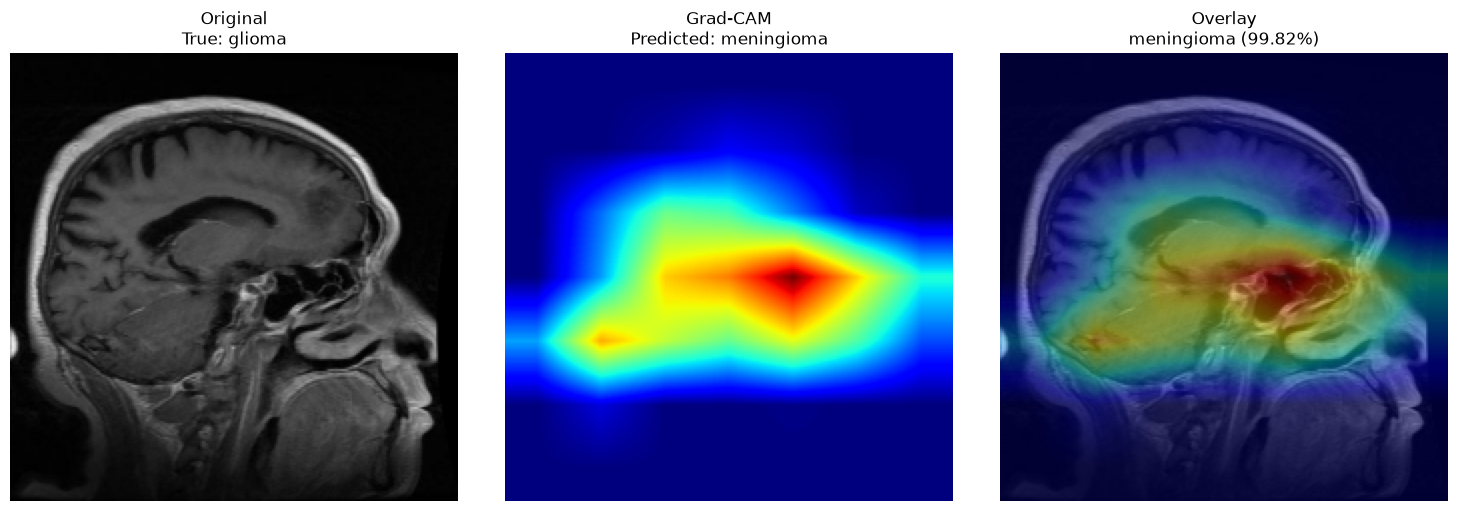

In [33]:
highest_error_index = (
    high_confidence_errors.index[0]
)

error_image = all_images[
    highest_error_index
]

error_true_class = all_labels[
    highest_error_index
]

error_predicted_class = all_predictions[
    highest_error_index
]

error_heatmap, _, error_probabilities = (
    make_gradcam_heatmap(
        error_image[np.newaxis, ...]
    )
)

display_gradcam(
    image=error_image,
    heatmap=error_heatmap,
    true_class=error_true_class,
    predicted_class=error_predicted_class,
    probabilities=error_probabilities
)

#### Select glioma → meningioma error

In [34]:
glioma_meningioma_indices = (
    results_df.index[
        (results_df["true_class"] == "glioma")
        &
        (results_df["predicted_class"] == "meningioma")
    ]
)

print(
    "Number of glioma → meningioma errors:",
    len(glioma_meningioma_indices)
)

Number of glioma → meningioma errors: 22


#### Visualize glioma → meningioma cases

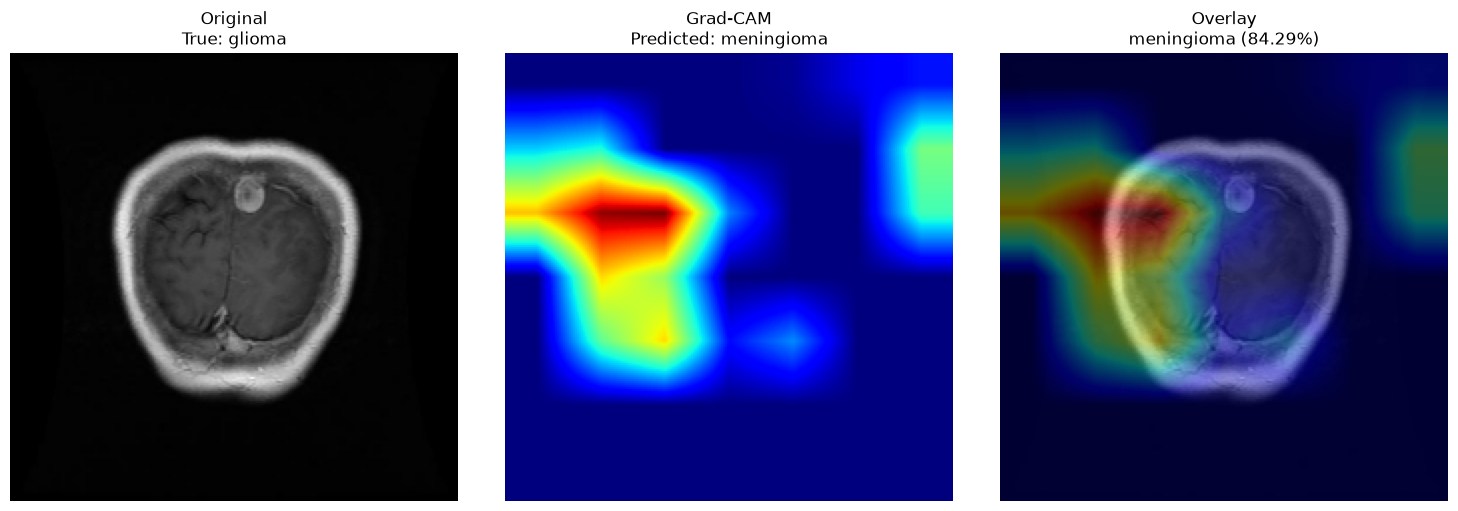

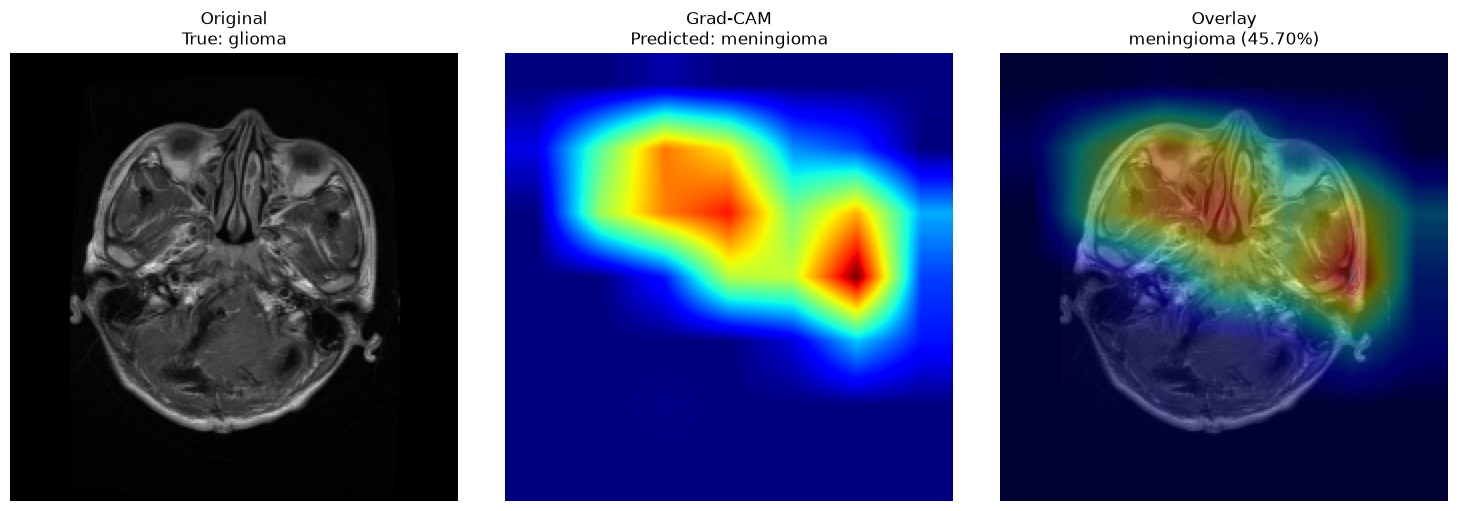

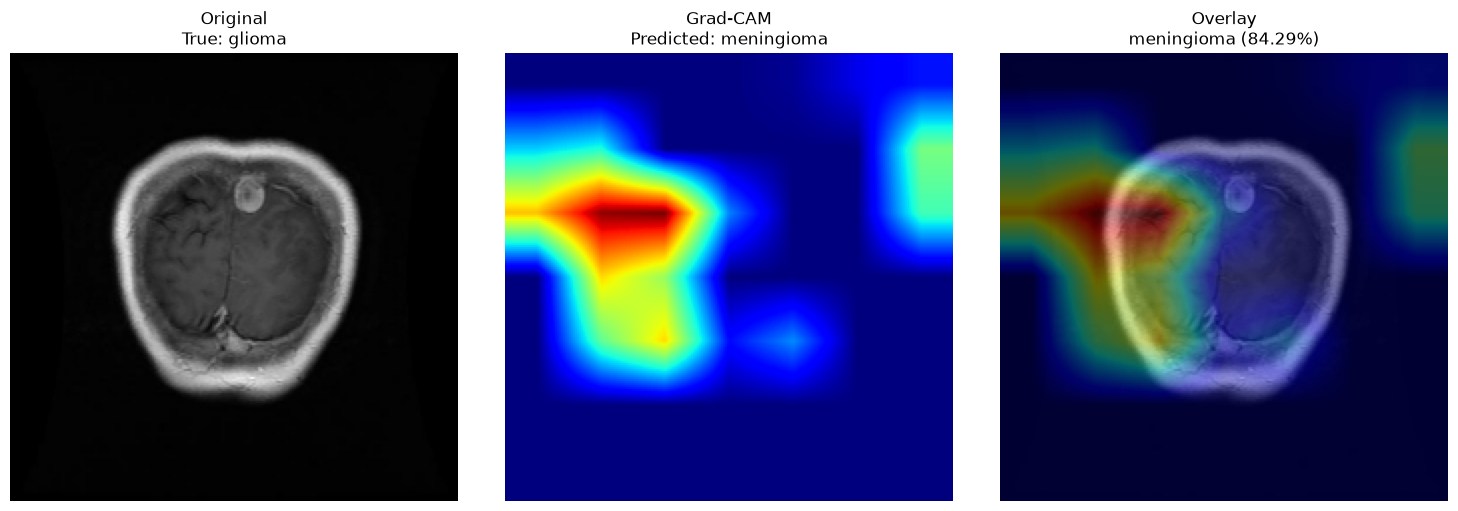

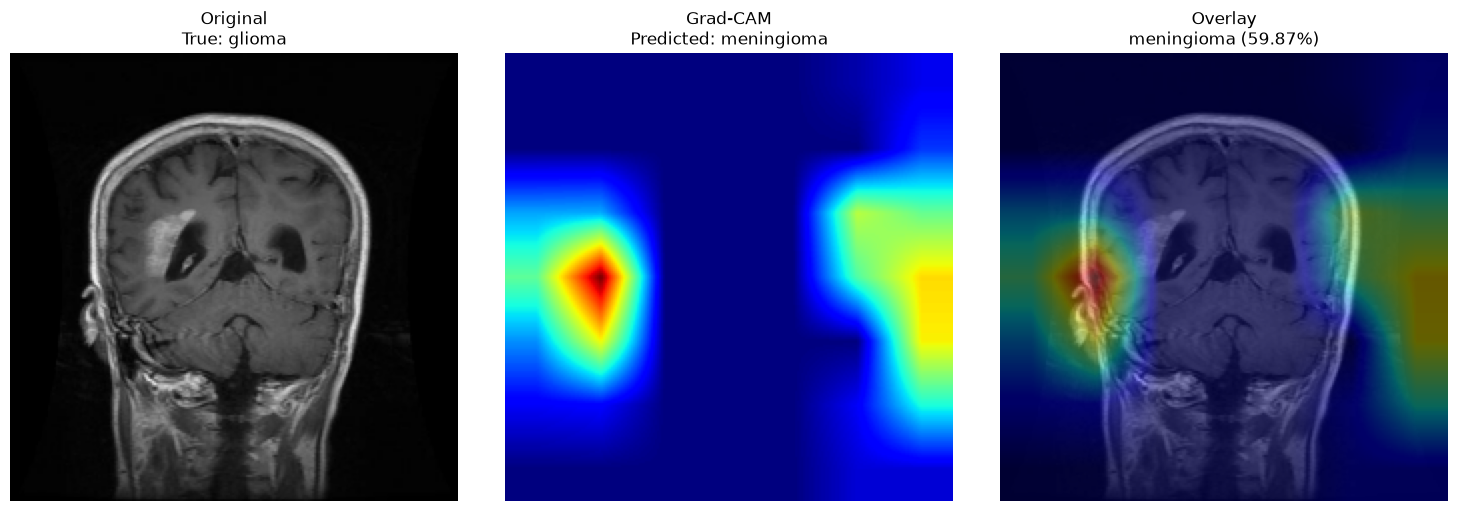

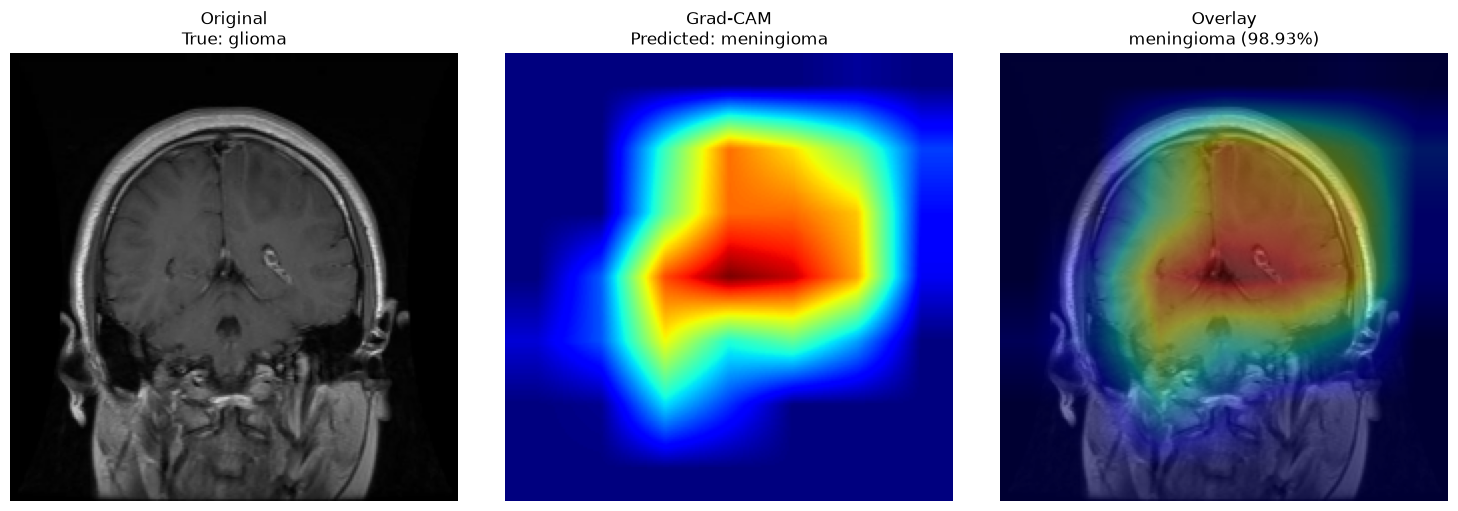

In [35]:
num_cases = min(
    5,
    len(glioma_meningioma_indices)
)

for index in glioma_meningioma_indices[:num_cases]:

    image = all_images[index]

    true_class = all_labels[index]

    predicted_class = all_predictions[index]

    heatmap, _, probabilities = (
        make_gradcam_heatmap(
            image[np.newaxis, ...]
        )
    )

    display_gradcam(
        image=image,
        heatmap=heatmap,
        true_class=true_class,
        predicted_class=predicted_class,
        probabilities=probabilities
    )

#### Correct glioma examples

In [36]:
correct_glioma_indices = (
    results_df.index[
        (results_df["true_class"] == "glioma")
        &
        (results_df["predicted_class"] == "glioma")
    ]
)

print(
    "Correctly classified glioma images:",
    len(correct_glioma_indices)
)

Correctly classified glioma images: 229


#### Visualize correct glioma cases

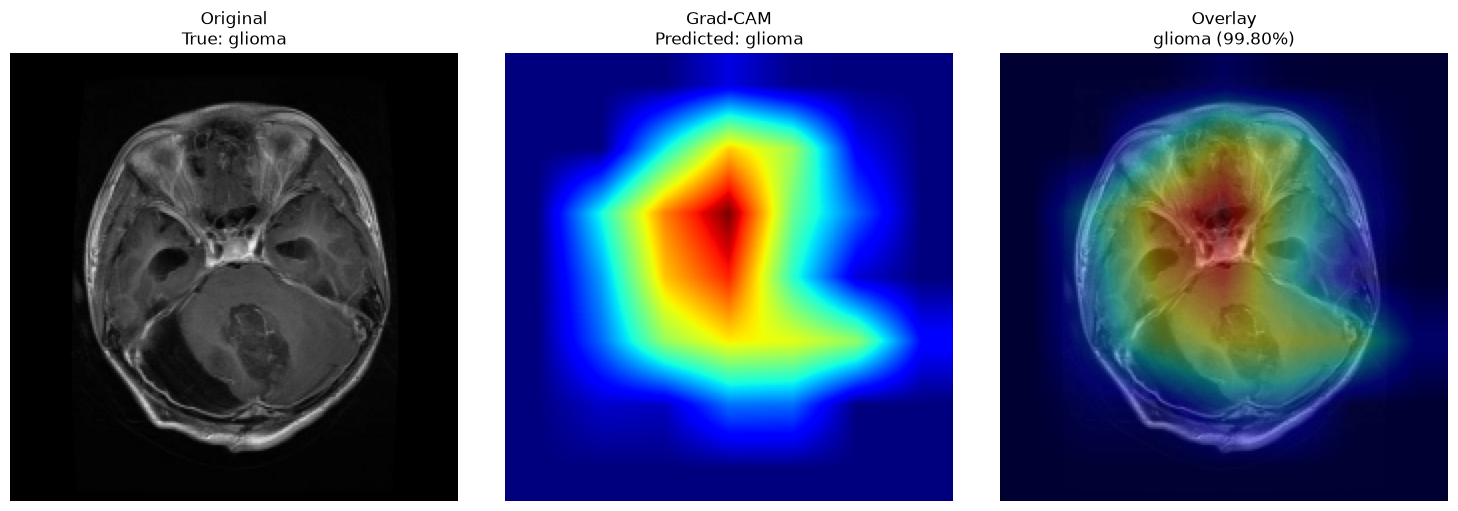

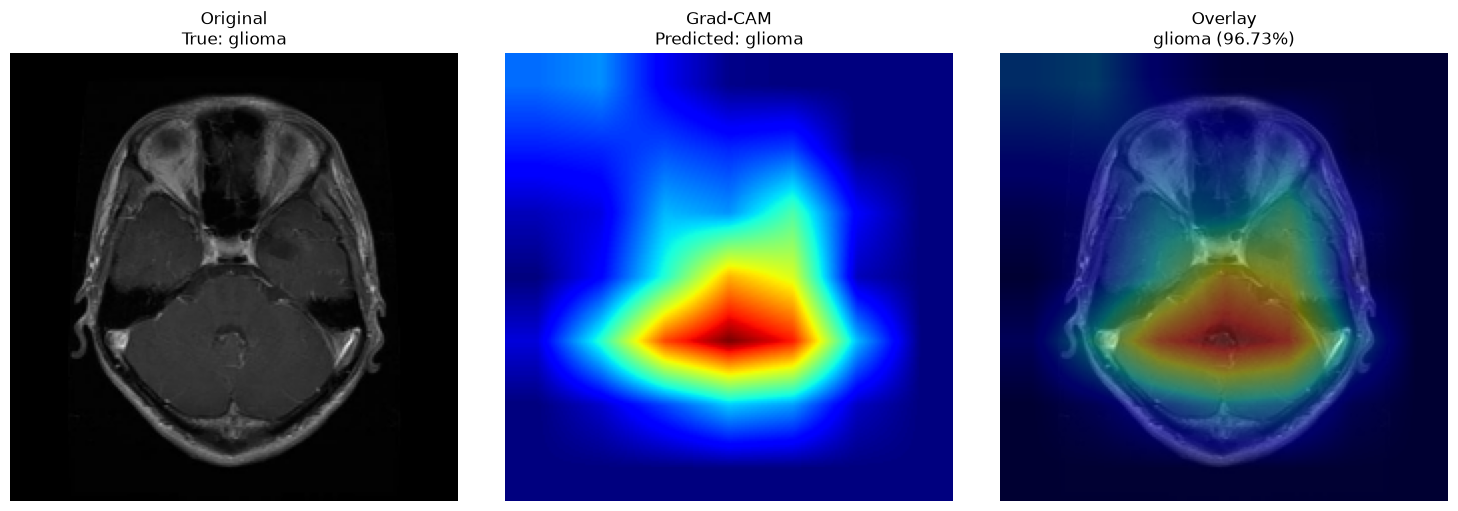

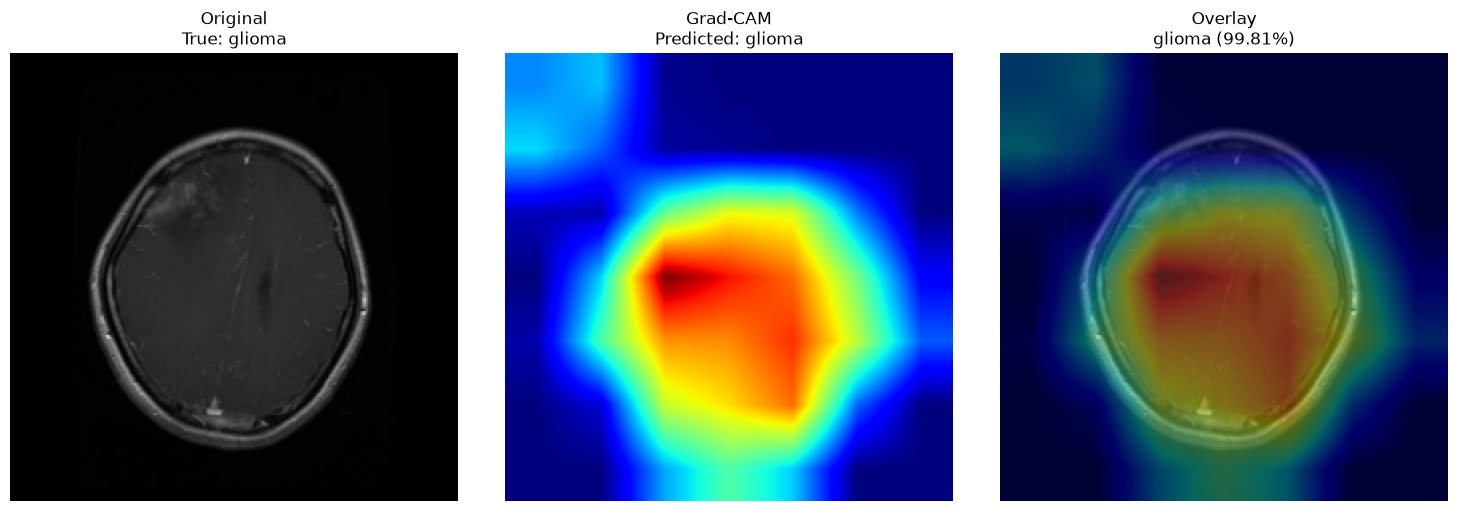

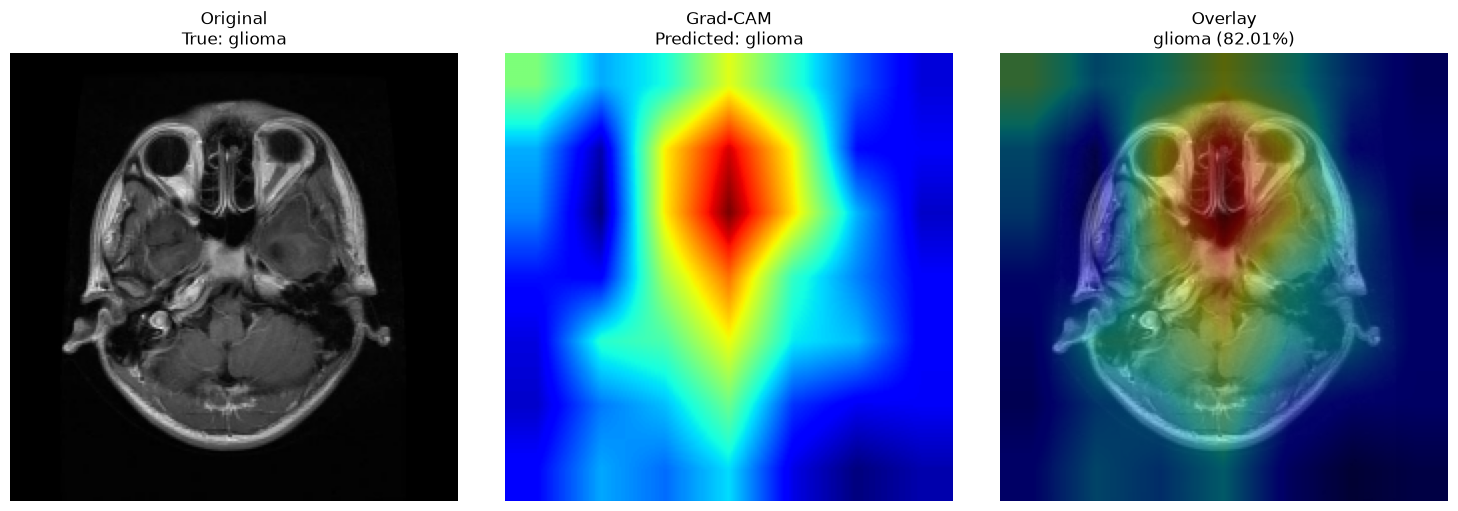

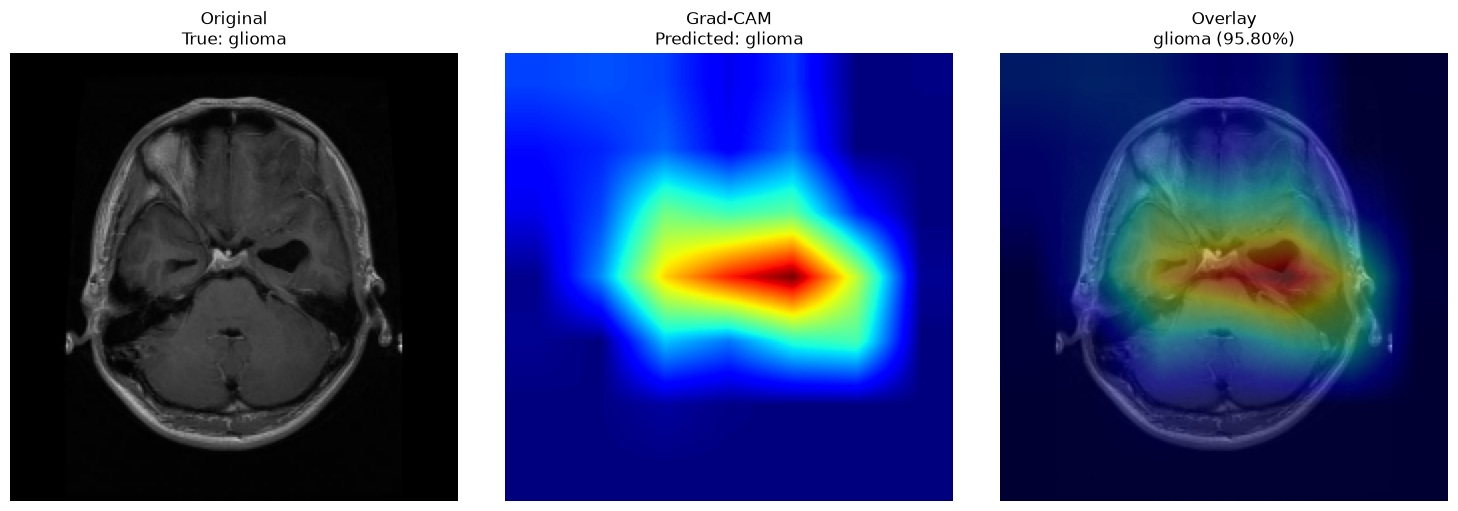

In [37]:
num_cases = min(
    5,
    len(correct_glioma_indices)
)

for index in correct_glioma_indices[:num_cases]:

    image = all_images[index]

    true_class = all_labels[index]

    predicted_class = all_predictions[index]

    heatmap, _, probabilities = (
        make_gradcam_heatmap(
            image[np.newaxis, ...]
        )
    )

    display_gradcam(
        image=image,
        heatmap=heatmap,
        true_class=true_class,
        predicted_class=predicted_class,
        probabilities=probabilities
    )

#### Analyze confidence of glioma → meningioma errors

In [38]:
glioma_meningioma_errors = results_df[
    (results_df["true_class"] == "glioma")
    &
    (results_df["predicted_class"] == "meningioma")
].copy()

glioma_meningioma_errors = (
    glioma_meningioma_errors
    .sort_values(
        "confidence",
        ascending=False
    )
)

glioma_meningioma_errors[
    [
        "true_class",
        "predicted_class",
        "confidence"
    ]
]

,true_class,predicted_class,confidence
234,glioma,meningioma,0.998250
95,glioma,meningioma,0.989304
148,glioma,meningioma,0.977056
245,glioma,meningioma,0.967706
161,glioma,meningioma,0.956771
145,glioma,meningioma,0.947605
250,glioma,meningioma,0.881112
165,glioma,meningioma,0.856726
236,glioma,meningioma,0.853915
230,glioma,meningioma,0.852411


#### Interpretability Findings

##### Final V2 model

The final fine-tuned ResNet50 achieved:

- Test accuracy: 94.6%
- Total test samples: 1000
- Total errors: 54

##### Error analysis

- Glioma → meningioma: 22 cases
- Tumor → no_tumor: 6 cases
- no_tumor → tumor: 0 cases

The largest remaining error pattern is glioma being classified as meningioma.

##### Grad-CAM

Grad-CAM was used to qualitatively inspect the regions contributing to the model's predictions.

The target layer was:

`conv5_block3_3_conv`

The target activation has spatial dimensions:

`7 × 7`

The analysis compared:

1. Correctly classified glioma cases.
2. Glioma → meningioma errors.
3. High-confidence incorrect predictions.

##### Interpretation

Grad-CAM can help identify whether the model appears to rely on relevant image regions or potentially irrelevant regions.

However, these heatmaps are qualitative. They do not establish:

- clinical validity,
- tumor segmentation accuracy,
- causal reasoning,
- diagnostic reliability,
- or that the highlighted region is definitely the tumor.

Therefore, Grad-CAM is treated as an interpretability tool rather than clinical evidence.